In [2]:
def Whatsapp_Analyzer(file):
    import pandas  as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    from sklearn.feature_extraction.text import TfidfVectorizer
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
    from sklearn.decomposition import NMF
    from sklearn.feature_extraction.text import HashingVectorizer
    import pickle
    from wordcloud import WordCloud
    import nltk
    from nltk.corpus import stopwords
    
    # loading file
    with open(file, "r", encoding="utf-8") as file:
        chat = file.readlines()
    df = pd.DataFrame(chat, columns=["Chat"])
    Date=df["Chat"].str.split(",",n=1,expand=True)
    Time=Date[1].str.split("-",n=1,expand=True)
    Name=Time[1].str.split(":",n=1,expand=True)
    df=df.drop(0)
    df["Date"]=Date[0]
    df["Time"]=Time[0]
    df["Name"]=Name[0]
    df["Chat"]=Name[1]
    df=df[["Date","Time","Name","Chat"]]
    df["Chat"] = df["Chat"].str.strip()
    df.dropna(inplace=True)
    dataset=df

    #Analyze
    sns.countplot(dataset,x="Date",hue="Name")
    plt.title("Date Wise Message Count")
    plt.show()
    print("Flirt Encounters:")
    talkative=dataset["Name"].value_counts().idxmax()
    print("Talkative:",talkative)
    less_talkative=dataset["Name"].value_counts().idxmin()
    print("Less Talkative:",less_talkative)
    print("Time Encounters:")
    active_date=dataset["Date"].value_counts().idxmax()
    print("Most Active Date:",active_date)
    active_hour=dataset["Time"].value_counts().idxmax()
    active=active_hour.replace("\u202f","")
    print("Most Active Hour:",active)
    avg_msg=dataset.groupby("Date")["Chat"].count().mean()
    print("Average Number of Message per Day:",avg_msg)
    print("Media Encounters:")
    media_count=dataset[dataset["Chat"].str.contains("file attached",case=True,na=False)]
    media_count_person=media_count.groupby("Name")["Chat"].count()
    print("Media Count:")
    for name,count in media_count_person.items():
        print(f"{name}: {count}")
    deleted_message=(dataset["Chat"]=="You deleted this message").sum()
    if deleted_message>0:
        print("Deleted Message Count:",deleted_message)
    else:
        print(f"Deleted Message Count: No Message was deleted")
    voice_call=dataset[dataset["Chat"]=="Missed voice call"].shape[0]
    if voice_call>0:
        print("Missed Voice Call Count:",voice_call)
    else:
        print(f"Missed Voice Call Count: No Missed Voice call")
    video_call=dataset[dataset["Chat"]=="Missed video call"].shape[0]
    if video_call>0:
        print("Missed Video Call Count:",video_call)
    else:
        print(f"Missed Video Call Count: No Missed Video call")
    
    #load model and predict
    loaded_model=pickle.load(open("finalized_model_decision_tree.sav",'rb'))
    hash_vectorizer=HashingVectorizer(n_features=10, norm=None, alternate_sign=False,stop_words='english')
    hash_train = hash_vectorizer.fit_transform(dataset["Chat"])
    Prediction=loaded_model.predict(hash_train)
    dataset["Label"]=Prediction

    #Sentiment Analysis
    data=dataset.copy()
    sid = SentimentIntensityAnalyzer()
    #Deleting null pr empty value
    data.dropna(inplace=True)
    
    #Creating respective columns
    data['scores'] = data["Chat"].apply(lambda commentText: sid.polarity_scores(commentText))
    data['compound']  = data['scores'].apply(lambda score_dict: score_dict['compound'])
    data['Negtive']  = data['scores'].apply(lambda score_dict: score_dict['neg'])
    data['Postive']  = data['scores'].apply(lambda score_dict: score_dict['pos'])
    data['Neutral']  = data['scores'].apply(lambda score_dict: score_dict['neu'])
    
    #Creating final pos or neg using compound score
    data['comp_score'] = data['compound'].apply(lambda c: 'pos' if c >=0 else 'neg')

    #plotting graph
    print("Sentimental Analysis:")
    graph=sns.countplot(data,x=data["comp_score"],hue="Name")
    plt.show()

    #topic modelling
    print("Topic Modelling:")
    tfidf=TfidfVectorizer(max_df=0.95,min_df=2,stop_words='english')
    dtm=tfidf.fit_transform(data["Chat"])
    nmf_model=NMF(n_components=4,random_state=42)
    nmf_model.fit(dtm)
    for index,topic in enumerate(nmf_model.components_):
        results=([tfidf.get_feature_names_out()[i] for i in topic.argsort()[-10:]])
        print(results)
        
    #wordcloud
    nltk.download('stopwords')
    comment_words = []
    stoplist = stopwords.words('english')
    stoplist.extend(['omitted', 'voice','missed','call','video','deleted','media','message'])
    wordcloudss="This function saves image"
    # Combine all chat messages
    comment_words = data['Chat'].dropna().astype(str)
    vv = " ".join(comment_words)          
    wordcloud = WordCloud(width = 800, height = 800, 
                                    background_color ='white', 
                                          stopwords = stoplist, 
                                          min_font_size = 10).generate(vv)         
    plt.figure(figsize = (9, 7), facecolor = None)
    plt.imshow(wordcloud)
    plt.axis("off") 
    plt.tight_layout(pad = 0) 
    plt.savefig('wordcloud.PNG')
    plt.show() 
    wordcloudss="This function saves image"
   
    return dataset,graph,results,wordcloud
 

    

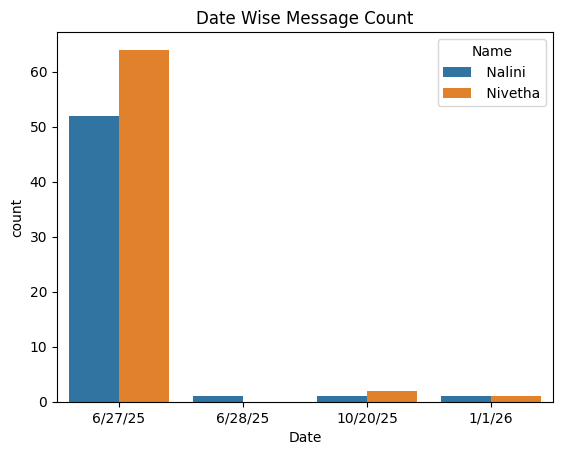

Flirt Encounters:
Talkative:  Nivetha
Less Talkative:  Nalini
Time Encounters:
Most Active Date: 6/27/25
Most Active Hour:  2:50PM 
Average Number of Message per Day: 30.5
Media Encounters:
Media Count:
 Nalini: 1
 Nivetha: 5
Deleted Message Count: No Message was deleted
Missed Voice Call Count: No Missed Voice call
Missed Video Call Count: No Missed Video call
Sentimental Analysis:


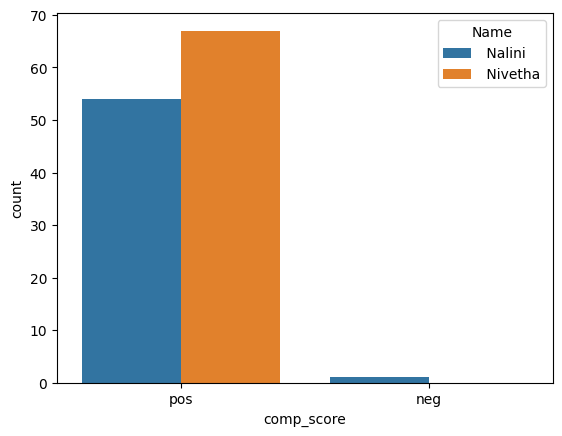

Topic Modelling:
['ta', 'send', 'aama', 'la', 'ena', 'nalla', 'ok', 'ila', 'work', 'da']
['enga', 'ah', 'kuda', 'paiyan', 'ellarum', 'pandra', 'enna', 'wrk', 'da', 'okok']
['amma', 'da', 'iruka', 'ta', 'ellartayum', 'irupa', 'epd', 'pesuviya', 'ippo', 'nee']
['marriage', 'ae', 'contact', 'ila', 'stk', '20250627', 'jpg', 'img', 'file', 'attached']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


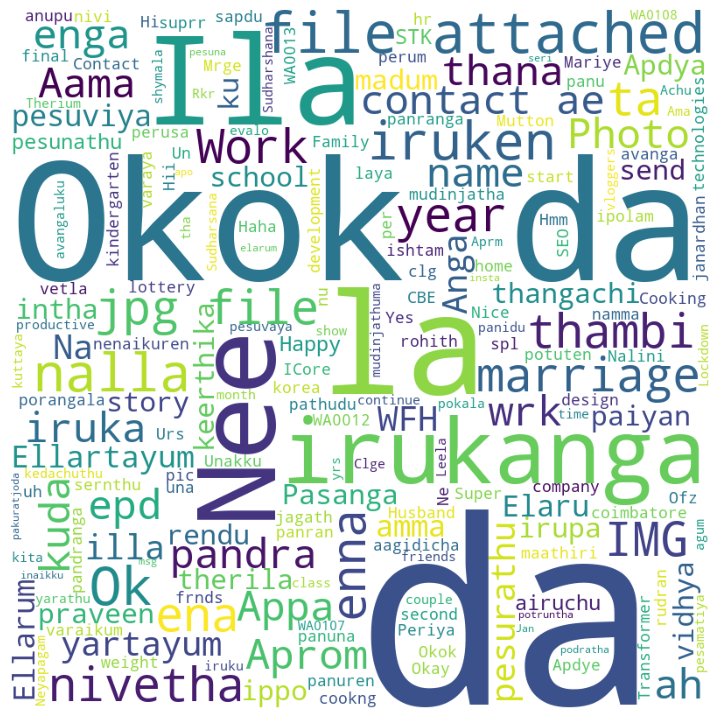

In [10]:
df,graph,results,wordcloud=Whatsapp_Analyzer("WhatsApp Chat with Nalini.txt")

In [6]:
df

,Date,Time,Name,Chat,Label
2,6/27/25,2:14 PM,Nalini,Hii d,Normal
3,6/27/25,2:14 PM,Nivetha,Hi Nalini epd iruka,Flirty
4,6/27/25,2:16 PM,Nalini,Nalla iruken nivi,Flirty
5,6/27/25,2:16 PM,Nalini,Nee,Normal
6,6/27/25,2:17 PM,Nivetha,Ok da..nalla iruken da,Normal
...,...,...,...,...,...
120,10/20/25,10:20 AM,Nivetha,STK-20251020-WA0010.was (file attached),Flirty
121,10/20/25,10:27 AM,Nalini,Happy diwali 🎇,Normal
122,10/20/25,10:31 AM,Nivetha,Thanks da🥰,Normal
123,1/1/26,8:43 AM,Nivetha,STK-20260101-WA0016.webp (file attached),Flirty
